In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [39]:
# Load your raw dataset (adjust path/filename based on your Kaggle download)
# Assumes rows are samples and columns are genes (or vice versa)
df_raw = pd.read_csv("../Data/fibrosis_smoc2_rawcounts.csv")
print("Read CSV file Successfully")

#Print shapes and a preview to see what we are dealing with
print(f"Dataset Shape: {df_raw.shape}")
print(df_raw.head())

Read CSV file Successfully
Dataset Shape: (47729, 8)
           Unnamed: 0  smoc2_fibrosis1  smoc2_fibrosis4  smoc2_normal1  \
0  ENSMUSG00000102693                0                0              0   
1  ENSMUSG00000064842                0                0              0   
2  ENSMUSG00000051951               72               30              0   
3  ENSMUSG00000102851                0                0              0   
4  ENSMUSG00000103377                0                0              1   

   smoc2_normal3  smoc2_fibrosis3  smoc2_normal4  smoc2_fibrosis2  
0              0                0              0                0  
1              0                0              0                0  
2              3               36              1               51  
3              0                0              0                0  
4              0                0              0                0  


### Data Cleaning & Transposition

In [40]:
import pandas as pd
import numpy as np

In [41]:
# 1. Clean up column names and set the Ensembl Gene IDs as the index
df = df_raw.rename(columns={'Unnamed: 0': 'gene_id'})
df.set_index('gene_id', inplace=True)

In [42]:
print(df.head())

                    smoc2_fibrosis1  smoc2_fibrosis4  smoc2_normal1  \
gene_id                                                               
ENSMUSG00000102693                0                0              0   
ENSMUSG00000064842                0                0              0   
ENSMUSG00000051951               72               30              0   
ENSMUSG00000102851                0                0              0   
ENSMUSG00000103377                0                0              1   

                    smoc2_normal3  smoc2_fibrosis3  smoc2_normal4  \
gene_id                                                             
ENSMUSG00000102693              0                0              0   
ENSMUSG00000064842              0                0              0   
ENSMUSG00000051951              3               36              1   
ENSMUSG00000102851              0                0              0   
ENSMUSG00000103377              0                0              0   

                  

In [43]:
# 2. Filtering Noise: Remove genes that have 0 expression across ALL samples
# Out of 47k+ genes, thousands will be completely silent. Let's drop them.
df = df[df.sum(axis=1) > 0]
print(f"Shape after filtering zero-expression genes: {df.shape}")

Shape after filtering zero-expression genes: (29556, 7)


In [44]:
# 3. Normalization (CPM: Counts Per Million)
# Raw counts vary based on sequencing machine depth. We scale each column to its sum.
cpm_df = df.divide(df.sum(axis=0), axis=1) * 1_000_000

In [45]:
print(cpm_df.head())

                    smoc2_fibrosis1  smoc2_fibrosis4  smoc2_normal1  \
gene_id                                                               
ENSMUSG00000051951         2.602022         1.389916       0.000000   
ENSMUSG00000103377         0.000000         0.000000       0.051324   
ENSMUSG00000103147         0.036139         0.046331       0.051324   
ENSMUSG00000103161         0.000000         0.046331       0.000000   
ENSMUSG00000102331         0.325253         0.092661       0.051324   

                    smoc2_normal3  smoc2_fibrosis3  smoc2_normal4  \
gene_id                                                             
ENSMUSG00000051951       0.135988         1.472315       0.041676   
ENSMUSG00000103377       0.000000         0.000000       0.000000   
ENSMUSG00000103147       0.000000         0.040898       0.000000   
ENSMUSG00000103161       0.000000         0.000000       0.000000   
ENSMUSG00000102331       0.045329         0.286283       0.041676   

                  

In [46]:
# 4. Log Transformation (Log2(CPM + 1))
# Stabilizes variance across highly expressed and lowly expressed genes
log_df = np.log2(cpm_df + 1)

In [47]:
# 5. Transpose the Matrix for Scikit-Learn (Flipped so Rows=Samples, Columns=Genes)
df_ml = log_df.T

In [48]:
# 6. Extract Target Labels (Y) from the original column names
# Creates 1 for fibrosis, 0 for normal
y = np.array([1 if 'fibrosis' in sample else 0 for sample in df_ml.index])

In [49]:
print(f"\nFinal ML Feature Matrix Shape (Samples, Genes): {df_ml.shape}")
print(f"Target vector labels (0 = Normal, 1 = Fibrosis): {y}")


Final ML Feature Matrix Shape (Samples, Genes): (7, 29556)
Target vector labels (0 = Normal, 1 = Fibrosis): [1 1 0 0 1 0 1]


### Exploratory Data Analysis (EDA) & Finding SMOC2
#### Because this dataset is high-dimensional (thousands of features, but only 7 rows), we can't look at individual scatter plots for every gene. Instead, we use two methods:
#### 1. Find SMOC2: Locate the exact Ensembl identifier for SMOC2 to verify how it behaves between your normal and fibrotic samples.
#### 2. PCA (Principal Component Analysis): Reduce all 29,556 dimensions down to 2 dimensions to see if the biological patterns cleanly separate the "Healthy" samples from the "Fibrosis" samples.


In [50]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

Found SMOC2 (ENSMUSG00000023886) in the dataset!


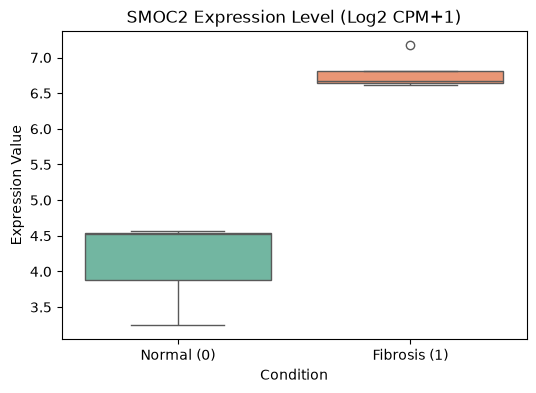

In [51]:
# --- 1. Find SMOC2 Gene Expression ---
# Mouse Smoc2 Ensembl ID (verified against MGI/NCBI): ENSMUSG00000023886
smoc2_id = 'ENSMUSG00000023886'

if smoc2_id in df_ml.columns:
    print(f"Found SMOC2 ({smoc2_id}) in the dataset!")
    # Plotting SMOC2 expression across conditions
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=y, y=df_ml[smoc2_id], hue=y, palette="Set2", legend=False)
    plt.xticks([0, 1], ['Normal (0)', 'Fibrosis (1)'])
    plt.title("SMOC2 Expression Level (Log2 CPM+1)")
    plt.ylabel("Expression Value")
    plt.xlabel("Condition")
    plt.savefig("../images/SMOC2 Expression Level.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print(f"{smoc2_id} not found in the filtered matrix. Check that the gene was not dropped by the zero-expression filter.")

In [52]:
# --- 2. Principal Component Analysis (PCA) ---
# Scale features before PCA (mean=0, variance=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_ml)

In [53]:
# Reduce to 2 Principal Components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

In [54]:
# Create a DataFrame for plotting the PCA results
df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca['Condition'] = ['Fibrosis' if val == 1 else 'Normal' for val in y]

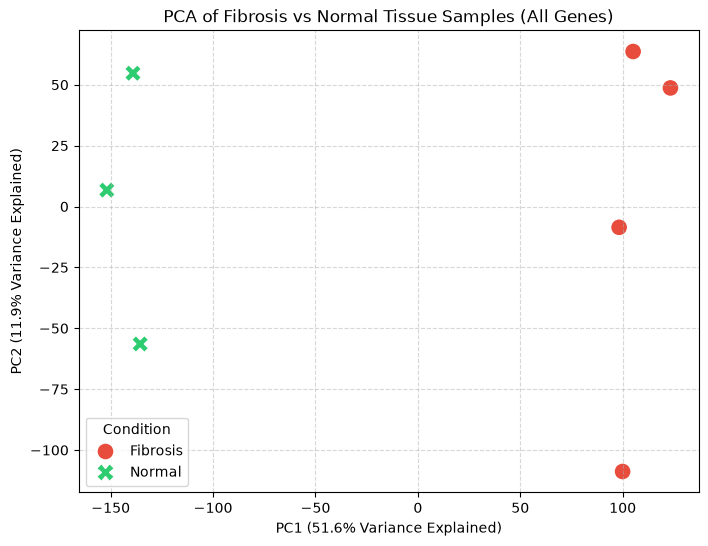

In [55]:
# Plot the PCA space
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_pca, 
    x='PC1', 
    y='PC2', 
    hue='Condition', 
    style='Condition', 
    s=150, 
    palette=['#e74c3c', '#2ecc71']
)
plt.title("PCA of Fibrosis vs Normal Tissue Samples (All Genes)")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance Explained)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance Explained)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Creating and Training the Classification Model

In [56]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import accuracy_score
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# 1. Initialize Logistic Regression with a relaxed L1 penalty
# Increasing C to 1.0 reduces the penalty, allowing the model to keep the most important genes.
model = LogisticRegression(l1_ratio=1, solver='liblinear', C=1.0, max_iter=1000, random_state=42)

# 2. Cross-Validation (Leave-One-Out)
loo = LeaveOneOut()
y_true, y_pred = [], []

for train_idx, test_idx in loo.split(df_ml):
    X_train, X_test = df_ml.iloc[train_idx], df_ml.iloc[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    
    # Scale within cross-validation to prevent data leakage
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Train and predict
    model.fit(X_train_scaled, y_train)
    y_pred.append(model.predict(X_test_scaled)[0])
    y_true.append(y_test[0])

# Calculate total baseline accuracy
cv_accuracy = accuracy_score(y_true, y_pred)
print(f"📊 Leave-One-Out Cross-Validation Accuracy: {cv_accuracy * 100:.1f}%")

# 3. Extract the Predictive Gene Signature
scaler_full = StandardScaler()
X_full_scaled = scaler_full.fit_transform(df_ml)
model.fit(X_full_scaled, y)

# Find columns where coefficients are not zero
coefficients = model.coef_[0]
selected_indices = np.where(coefficients != 0)[0]
selected_genes = df_ml.columns[selected_indices]
selected_weights = coefficients[selected_indices]

# Combine into a clean summary dataframe
signature_df = pd.DataFrame({
    'Gene_Ensembl_ID': selected_genes,
    'Model_Weight': selected_weights
}).sort_values(by='Model_Weight', key=abs, ascending=False)

print(f"\n🧬 The model selected {len(signature_df)} top predictive genes:")
print(signature_df.to_string(index=False))

📊 Leave-One-Out Cross-Validation Accuracy: 100.0%

🧬 The model selected 91 top predictive genes:
   Gene_Ensembl_ID  Model_Weight
ENSMUSG00000030255      1.116470
ENSMUSG00000068739      0.092687
ENSMUSG00000031422      0.081391
ENSMUSG00000055737     -0.069485
ENSMUSG00000059208      0.031942
ENSMUSG00000074916      0.024387
ENSMUSG00000028274      0.020418
ENSMUSG00000043289      0.019496
ENSMUSG00000020051     -0.017822
ENSMUSG00000087179      0.016791
ENSMUSG00000035529      0.016532
ENSMUSG00000038429      0.016081
ENSMUSG00000022142      0.015957
ENSMUSG00000006498      0.015372
ENSMUSG00000006342     -0.015352
ENSMUSG00000027510      0.014373
ENSMUSG00000026639      0.014333
ENSMUSG00000035683      0.013271
ENSMUSG00000000976      0.012076
ENSMUSG00000021359      0.010070
ENSMUSG00000024056      0.009769
ENSMUSG00000060397      0.009288
ENSMUSG00000035673      0.008929
ENSMUSG00000046093      0.008507
ENSMUSG00000033831      0.008466
ENSMUSG00000044456      0.008181
ENSMUSG00000

### Step 5: Validating the Result (Gene Stability & Permutation Test)

#### In this section, we will validate the robustness of our Logistic Regression model. We will check how consistently genes are selected across all Leave-One-Out folds, perform an exact permutation test to check whether the accuracy could be a chance result, and check where SMOC2, a known fibrosis gene, falls relative to the selected genes and specifically locate our primary biomarker (SMOC2) within the final predictive signature.

#### Validating the Result: Gene Stability Across LOO Folds
##### Which selected genes are chosen in every fold, rather than just in the full-data fit?

In [57]:
model = LogisticRegression(l1_ratio=1, solver='liblinear', C=1.0, max_iter=1000, random_state=42)

picked = []
for tr, te in LeaveOneOut().split(df_ml):
    sc = StandardScaler().fit(df_ml.iloc[tr])
    model.fit(sc.transform(df_ml.iloc[tr]), y[tr])
    picked.append(set(np.where(model.coef_[0] != 0)[0]))

always = set.intersection(*picked)
print(f"Genes selected in all {len(picked)} folds: {len(always)}")
print(df_ml.columns[sorted(always)].tolist())

Genes selected in all 7 folds: 1
['ENSMUSG00000030255']


#### Validating the Result: Exact Permutation Test
##### With 7 samples there are only 35 possible label assignments, so we can test all of them.

In [58]:
from itertools import combinations

n, k = len(y), int(y.sum())
model = LogisticRegression(l1_ratio=1, solver='liblinear', C=1.0, max_iter=1000, random_state=42)

def loo_acc(labels):
    correct = 0
    for tr, te in LeaveOneOut().split(df_ml):
        sc = StandardScaler().fit(df_ml.iloc[tr])
        model.fit(sc.transform(df_ml.iloc[tr]), labels[tr])
        correct += model.predict(sc.transform(df_ml.iloc[te]))[0] == labels[te][0]
    return correct / n

accs = []
for pos in combinations(range(n), k):
    perm = np.zeros(n, dtype=int); perm[list(pos)] = 1
    accs.append(loo_acc(perm))

print(f"Real labels: {loo_acc(y):.1%}")
print(f"Share of all {len(accs)} labelings reaching ≥ real accuracy: {np.mean(np.array(accs) >= loo_acc(y)):.1%}")

Real labels: 100.0%
Share of all 35 labelings reaching ≥ real accuracy: 5.7%


#### Validating the Result: Stability Selection Across Sample Subsets
##### How often is each gene selected when we refit on every 5-sample subset (21 subsets × 3 values of C)?

In [61]:
from itertools import combinations
from collections import Counter

counts, n_fits = Counter(), 0
for C in [0.5, 1.0, 2.0]:
    for keep in combinations(range(len(y)), 5):
        keep = list(keep)
        sc = StandardScaler().fit(df_ml.iloc[keep])
        m = LogisticRegression(l1_ratio=1, solver='liblinear', C=C, max_iter=1000, random_state=42)
        m.fit(sc.transform(df_ml.iloc[keep]), y[keep])
        counts.update(np.where(m.coef_[0] != 0)[0]); n_fits += 1

freq = pd.Series({df_ml.columns[i]: c / n_fits for i, c in counts.items()}).sort_values(ascending=False)
print(f"Total fits: {n_fits}")
print(freq.head(15))
print("SMOC2 selection frequency:", freq.get('ENSMUSG00000023886', 0))

Total fits: 63
ENSMUSG00000030255    0.873016
ENSMUSG00000027510    0.365079
ENSMUSG00000028885    0.349206
ENSMUSG00000026639    0.222222
ENSMUSG00000044456    0.206349
ENSMUSG00000047098    0.190476
ENSMUSG00000017210    0.174603
ENSMUSG00000010936    0.174603
ENSMUSG00000015652    0.174603
ENSMUSG00000033885    0.174603
ENSMUSG00000020629    0.158730
ENSMUSG00000090213    0.158730
ENSMUSG00000022346    0.158730
ENSMUSG00000015647    0.158730
ENSMUSG00000024816    0.158730
dtype: float64
SMOC2 selection frequency: 0.015873015873015872


#### Biological Sanity Check: Top Gene and SMOC2

In [59]:
# SMOC2 check (mouse Smoc2 Ensembl ID)
smoc2_id = 'ENSMUSG00000023886'
top_gene = signature_df.iloc[0]['Gene_Ensembl_ID']

print("SMOC2 in matrix:", smoc2_id in df_ml.columns)
print("SMOC2 in selected signature:", smoc2_id in set(signature_df['Gene_Ensembl_ID']))
print(signature_df[signature_df['Gene_Ensembl_ID'] == smoc2_id])

print("\nSMOC2 log2(CPM+1) by condition:")
print(df_ml[smoc2_id].groupby(y).describe())
print("log2FC (fibrosis - normal):", df_ml.loc[y == 1, smoc2_id].mean() - df_ml.loc[y == 0, smoc2_id].mean())
print("Correlation of SMOC2 with top gene:", np.corrcoef(df_ml[smoc2_id], df_ml[top_gene])[0, 1])

print("\nTop gene:", top_gene)
print(df_ml[top_gene].groupby(y).describe())

SMOC2 in matrix: True
SMOC2 in selected signature: False
Empty DataFrame
Columns: [Gene_Ensembl_ID, Model_Weight]
Index: []

SMOC2 log2(CPM+1) by condition:
   count      mean       std       min       25%       50%       75%       max
0    3.0  4.113374  0.749717  3.248205  3.883982  4.519759  4.545959  4.572158
1    4.0  6.781576  0.263862  6.615447  6.641346  6.667923  6.808153  7.175013
log2FC (fibrosis - normal): 2.6682022831194185
Correlation of SMOC2 with top gene: 0.9747117656115839

Top gene: ENSMUSG00000030255
   count      mean       std       min       25%       50%       75%       max
0    3.0  2.047019  0.322258  1.682037  1.924383  2.166730  2.229510  2.292291
1    4.0  3.738266  0.181153  3.496952  3.664357  3.766141  3.840049  3.923828


### Step 6: Gene Shortlist for Interpretation
#### Top genes from the final model, flagged by whether they were selected in every LOO fold.

In [60]:
# Shortlist genes for interpretation, flagging fold-stable ones
stable_ids = set(df_ml.columns[sorted(always)])   # 'always' comes from the stability cell
top_10 = signature_df.head(10).copy()
top_10['Stable_in_all_folds'] = top_10['Gene_Ensembl_ID'].isin(stable_ids)
print(top_10.to_string(index=False))

   Gene_Ensembl_ID  Model_Weight  Stable_in_all_folds
ENSMUSG00000030255      1.116470                 True
ENSMUSG00000068739      0.092687                False
ENSMUSG00000031422      0.081391                False
ENSMUSG00000055737     -0.069485                False
ENSMUSG00000059208      0.031942                False
ENSMUSG00000074916      0.024387                False
ENSMUSG00000028274      0.020418                False
ENSMUSG00000043289      0.019496                False
ENSMUSG00000020051     -0.017822                False
ENSMUSG00000087179      0.016791                False
